<a href="https://colab.research.google.com/github/Rangan-Roy01/localrepo/blob/main/FirstSolved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
df=pd.read_csv("/Salary_dataset.csv")

In [6]:
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [8]:
df.drop("Unnamed: 0",axis=1,inplace=True)

In [9]:
df.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [10]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


In [11]:
df.isnull().sum()

,0
YearsExperience,0
Salary,0


In [12]:
df.corr()

,YearsExperience,Salary
YearsExperience,1.000000,0.978242
Salary,0.978242,1.000000


In [13]:
import seaborn as sns

/tmp/ipykernel_2011/738670369.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Salary"])


<Axes: xlabel='Salary', ylabel='Density'>

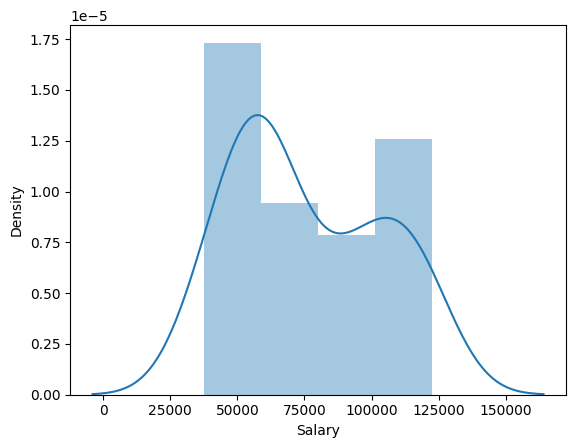

In [14]:
sns.distplot(df["Salary"])

/tmp/ipykernel_2011/1382351491.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["YearsExperience"])


<Axes: xlabel='YearsExperience', ylabel='Density'>

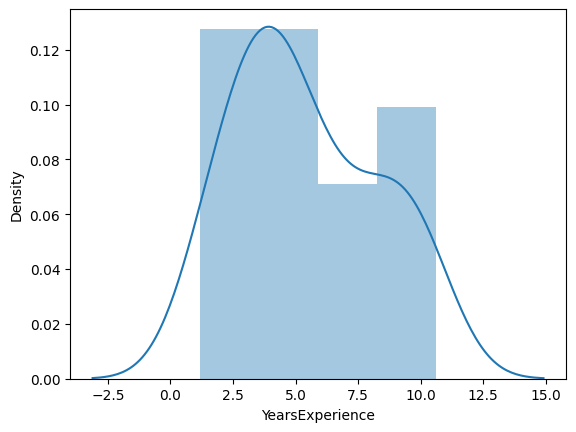

In [15]:
sns.distplot(df["YearsExperience"])

In [16]:
X=df[["YearsExperience"]]
y=df['Salary']

In [17]:
X

,YearsExperience
0,1.2
1,1.4
2,1.6
3,2.1
4,2.3
5,3.0
6,3.1
7,3.3
8,3.3
9,3.8


In [18]:
y

,Salary
0,39344.0
1,46206.0
2,37732.0
3,43526.0
4,39892.0
5,56643.0
6,60151.0
7,54446.0
8,64446.0
9,57190.0


In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [23]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((22, 1), (8, 1), (22,), (8,))

In [24]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [25]:
from sklearn.linear_model import LinearRegression
linreg=LinearRegression()
linreg.fit(X_train,y_train)

LinearRegression()

In [26]:
print(linreg.intercept_,linreg.coef_)

70417.40909090909 [25063.1519945]


In [27]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [28]:
y_pred=linreg.predict(X_test)

In [30]:
mse=

In [31]:
print("mse={}".format(mse))
print("mae={}".format(mae))
print("r2={}".format(r2))

mse=38802588.99247059
mae=5056.9954666635895
r2=0.9347210011126783


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


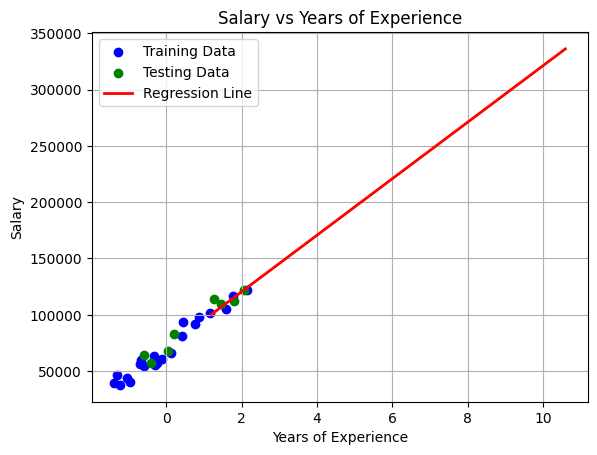

In [32]:
# Plot training data points
plt.scatter(X_train, y_train, color='blue', label='Training Data')
# Plot testing data points
plt.scatter(X_test, y_test, color='green', label='Testing Data')
# Plot the regression line
plt.plot(X, linreg.predict(X), color='red', linewidth=2, label='Regression Line')

plt.title('Salary vs Years of Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.savefig('linear_regression_fit.png')

In [33]:
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train,y_train)

Ridge()

In [34]:
y_ridge=ridge.predict(X_test)


In [35]:
mse=mean_squared_error(y_test,y_ridge)
mae=mean_absolute_error(y_test,y_ridge)
r2=r2_score(y_test,y_ridge)

In [36]:
print("mse={}".format(mse))
print("mae={}".format(mae))
print("r2={}".format(r2))

mse=43589362.951574214
mae=5459.800999733549
r2=0.9266680381516033


In [37]:
from sklearn.linear_model import LassoCV
lassocv=LassoCV()

In [38]:
lassocv.fit(X_train,y_train)

LassoCV()

In [39]:
y_pred=lassocv.predict(X_test)

In [40]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [41]:
print("mse={}".format(mse))
print("mae={}".format(mae))
print("r2={}".format(r2))

mse=38873409.228007086
mae=5066.259993924193
r2=0.9346018576689847


In [42]:
from sklearn.linear_model import ElasticNet
elastic=ElasticNet()
elastic.fit(X_train,y_train)

ElasticNet()

In [43]:
y_pred=elastic.predict(X_test)


In [44]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [45]:
print("mse={}".format(mse))
print("mae={}".format(mae))
print("r2={}".format(r2))

mse=164844026.91631842
mae=11196.179744974845
r2=0.7226769313836234


In [47]:
X_new=[[3.4]]
X_scaled=scaler.transform(X_new)
y_new=linreg.predict(X_scaled)
print("Predicted salary for 3.4 years of experience:", y_new[0])


Predicted salary for 3.4 years of experience: 56403.48049899918


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
